In [1]:
import os
os.chdir('/home/hedi/HSCNG/')
import numpy as np
from astropy.io import fits
from astropy.coordinates import SkyCoord
from astropy.wcs import WCS
from astropy import units as u
import matplotlib.pyplot as plt
import pprint
import pymaster as nmt
from hsc_y3_utils import stats_code
from hsc_y3_utils import map_utils

# Using the HSC_Y3_UTILS but not all the pipeline. 
## I checked the code and found something not correct

pipeline

pixelization -> inpainting -> KSI -> binary mask(use the original mask) -> smoothing

try results with & without inpainting

In [2]:
name_fields = ['XMM', 'VVDS','GAMA09H', 'GAMA15H', 'WIDE12H', 'HECTOMAP']
number_patches= [8, 25,23,7,26,13] # of each corresponding field

field = 'VVDS'
Npatch = 25
tomo_bin = [1, 2, 3, 4]         # tomo_bin, 0 is excluded.
dats = [
    fits.getdata(f'data/real/hscy3_shape_chopped_{field}_{i}.fits')
    for i in range(Npatch)
]
dat = np.concat(dats)

dat = dat[np.isin(dat['hsc_y3_zbin'], tomo_bin)]

# WCS

In [ ]:
# --- Input RA/Dec Range (degrees) ---
ra = dat['i_ra']
dec = dat['i_dec']
padding = 10  # pixels
pixscale_arcmin = 0.5   # 0.5 arcmin → degrees/pixel
pixscale_deg = pixscale_arcmin / 60.0

w, (nx, ny) = map_utils.set_wcs_shape(ra, dec, pixscale_arcmin, padding)

Image size: 3644 x 855
WCS Keywords

Number of WCS axes: 2
CTYPE : 'RA---TAN' 'DEC--TAN'
CUNIT : 'deg' 'deg'
CRVAL : 345.234601713302 2.408137905058622
CRPIX : 1825.0580419011992 421.81635077629267
PC1_1 PC1_2  : 1.0 0.0
PC2_1 PC2_2  : 0.0 1.0
CDELT : -0.008333333333333333 0.008333333333333333
NAXIS : 0  0


# shear map

In [6]:
flatgrid = map_utils.FlatClass(wcs=w, nx=nx, ny=ny)
pix = flatgrid.pos2pix(ra=dat['i_ra'], dec=dat['i_dec'])
ra_cat=dat['i_ra']
dec_cat=dat['i_dec']
weight_cat = dat['i_hsmshaperegauss_derived_weight']
m_cat = dat['i_hsmshaperegauss_derived_shear_bias_m']
erms_cat = dat['i_hsmshaperegauss_derived_rms_e']

e1_cat, e2_cat = dat['i_hsmshaperegauss_e1'], dat['i_hsmshaperegauss_e2']
c1_cat, c2_cat = dat['i_hsmshaperegauss_derived_shear_bias_c1'], dat['i_hsmshaperegauss_derived_shear_bias_c2']
flux_cat = dat['i_apertureflux_10_mag']
res_cat = dat['i_hsmshaperegauss_resolution']

psf11, psf12, psf22 = dat['i_sdssshape_psf_shape11'], dat['i_sdssshape_psf_shape12'], dat['i_sdssshape_psf_shape22']
epsf1_cat   = (psf11-psf22)/(psf11+psf22)
epsf2_cat   = (2*psf12)/(psf11+psf22)

# all kinds of calibrations and selection effect corrections
e1_hat, e2_hat =  map_utils.calib_shear_y3(weight_cat, m_cat, erms_cat, e1_cat, e2_cat, c1_cat, c2_cat, flux_cat, res_cat, epsf1_cat, epsf2_cat)

# weighted averaged shear map

## Shear map

In [7]:
[g1_map, g2_map], [mask, nmap] = map_utils.create_shear_map(ra_cat, dec_cat, e1_hat, e2_hat, flatgrid, weights=weight_cat)
# questions here: the mask shows whether there is galaxy, but we dont use the weight map afterwards.
mask_z = flatgrid.transform_mapsize(mask)
g1_map = flatgrid.transform_mapsize(g1_map)
g2_map = flatgrid.transform_mapsize(g2_map)

smoothing_kernel_size = 1  # arcmin
smoothing_pixels = smoothing_kernel_size / (pixscale_deg * 60)

g1_map = flatgrid.smooth_G(g1_map, smoothing_pixels)      # smoothed g1 map, 2d
g2_map = flatgrid.smooth_G(g2_map, smoothing_pixels)

In [8]:
size_rad_x = pixscale_deg / 180.0 * np.pi * nx
size_rad_y = pixscale_deg / 180.0 * np.pi * ny
ell_edges = np.unique(np.logspace(np.log10(80), np.log10(6500),15))
bins = nmt.bins.NmtBinFlat(ell_edges[:-1], ell_edges[1:])

ls = ell_edges[:-1] + np.diff(ell_edges)/2

In [ ]:
stat_gg = stats_code.compute_power_spectrum_spin2(g1_map, g2_map, mask_z, size_rad_x, size_rad_y, bins)

In [ ]:
np.savetxt(f'results/power_spectra/stat_gg_{field}.txt', np.T[ls, *stat_gg])

# kappa map

In [50]:
smooth_g = False
inpainting = True
smooth_k = False
procedure = []

if smooth_g:
    procedure.append('smooth g')
if inpainting:
    procedure.append('inpainting')
procedure.append('KSI-masking')
if smooth_k:
    procedure.append('smooth k')

procedure_str = '-'.join(procedure)

In [51]:
np.random.seed(42)

# pixelize shear map
[g1_map, g2_map], [mask, nmap] = map_utils.create_shear_map(ra_cat, dec_cat, e1_hat, e2_hat, flatgrid, weights=weight_cat)
# questions here: the mask shows whether there is galaxy, but we dont use the weight map afterwards.
mask_z = flatgrid.transform_mapsize(mask)
g1_map = flatgrid.transform_mapsize(g1_map)
g2_map = flatgrid.transform_mapsize(g2_map)

smoothing_kernel_size = 3  # arcmin
smoothing_pixels = smoothing_kernel_size / (pixscale_deg * 60)

# smoothing
if smooth_g:
    g1_map = flatgrid.smooth_G(g1_map, smoothing_pixels)      # smoothed g1 map, 2d
    g2_map = flatgrid.smooth_G(g2_map, smoothing_pixels)
if inpainting:
# Inpainting
    g1_map = map_utils.inpaint(g1_map*mask_z, mask_z, niter=100, thresholding='hard')
    g2_map = map_utils.inpaint(g2_map*mask_z, mask_z, niter=100, thresholding='hard')

# KS inversion
kappa, kappa_i = map_utils.KS_map(g1_map, g2_map)

# masking
kappa *= mask_z
kappa_i *= mask_z

if smooth_k:
    kappa = flatgrid.smooth_G(kappa.flatten(), smoothing_pixels)          # E mode
    kappa_i = flatgrid.smooth_G(kappa_i.flatten(), smoothing_pixels)      # B mode

# power spectrum

In [ ]:
size_rad_x = pixscale_deg / 180.0 * np.pi * nx
size_rad_y = pixscale_deg / 180.0 * np.pi * ny
ell_edges = np.unique(np.logspace(np.log10(80), np.log10(6500),15))
bins = nmt.bins.NmtBinFlat(ell_edges[:-1], ell_edges[1:])

# #Compute workspace, only run once when choosing the mask and bins
f0 = nmt.NmtFieldFlat(size_rad_x, size_rad_y, mask_z, [kappa]) 
wsp=nmt.NmtWorkspaceFlat()
wsp.compute_coupling_matrix(f0,f0,bins)

EE, BB, EB = stats_code.compute_ps_spin0_all_terms(kappa, kappa_i, mask.reshape(ny, nx), size_rad_x, size_rad_y, bins, wsp)
ls = ell_edges[:-1] + np.diff(ell_edges)/2

Text(0.5, 1.0, 'Field: VVDS, inpainting-KSI-masking')

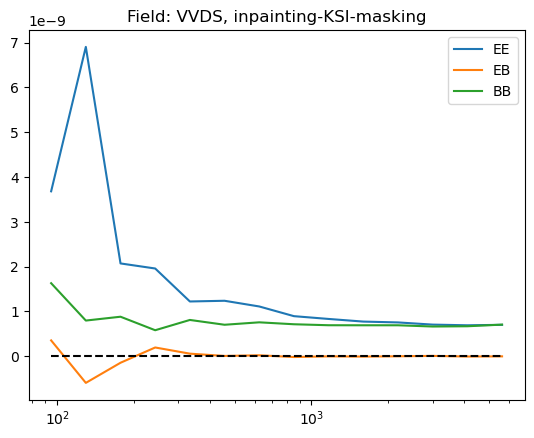

In [53]:
plt.plot(ls, EE, linestyle='-', label='EE')
plt.plot(ls, EB, linestyle='-', label='EB')
plt.plot(ls, BB, linestyle='-', label='BB')

plt.hlines(0, xmin=ls.min(), xmax=ls.max(), colors='k', linestyles='dashed')

plt.semilogx()
plt.legend()

plt.title(f'Field: {field}, {procedure_str}')

# plt.savefig(f'Cll_fig {procedure_str}.pdf')

# plot maps

In [54]:
# wcs_2, shape_2 = map_utils.set_wcs_shape(ra_cat, dec_cat, 0.5, pad= 1.0)
# nx_, ny_ = shape_2
# plt.scatter(*wcs_2.world_to_pixel(SkyCoord(ra=dat['i_ra']*u.deg, dec=dat['i_dec']*u.deg)))
# plt.hlines([0, ny_], xmin=0, xmax=nx_, colors='r')
# plt.vlines([0, nx_], ymin=0, ymax=ny_, colors='r')
# plt.show()

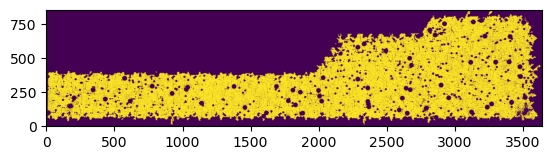

In [55]:
plt.imshow(mask_z, origin='lower')
plt.show()

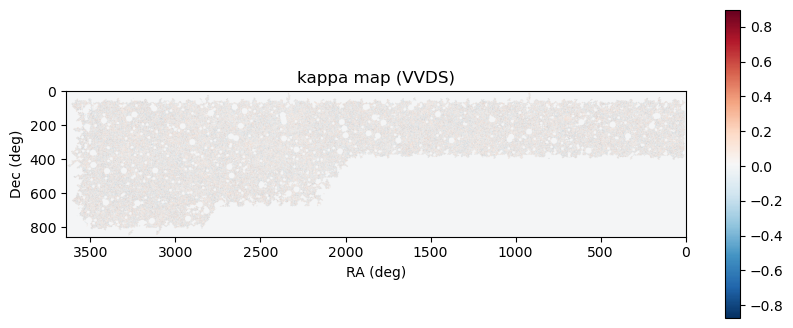

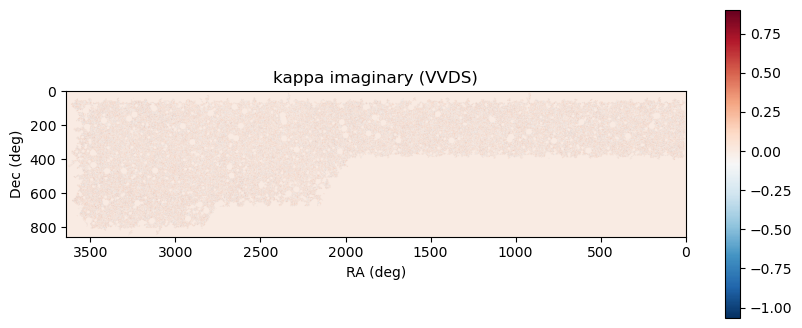

In [56]:
fig, ax = plt.subplots(figsize=(10, 4))
pcm = ax.imshow(kappa, cmap='RdBu_r')
cbar = fig.colorbar(pcm, ax=ax)
ax.set_xlabel('RA (deg)')
ax.set_ylabel('Dec (deg)')
ax.set_title(f'kappa map ({field})')
ax.set_aspect('equal', adjustable='box')
# RA often plotted increasing to the left — enable if desired
ax.invert_xaxis()
plt.show()
fig, ax = plt.subplots(figsize=(10, 4))
pcm = ax.imshow(kappa_i, cmap='RdBu_r')
cbar = fig.colorbar(pcm, ax=ax)
ax.set_xlabel('RA (deg)')
ax.set_ylabel('Dec (deg)')
ax.set_title(f'kappa imaginary ({field})')
ax.set_aspect('equal', adjustable='box')
# RA often plotted increasing to the left — enable if desired
ax.invert_xaxis()
plt.show()

# performing the same measurement with randomly rotated g

In [57]:
import tqdm

In [58]:
# shear_random = map_utils.random_rotation(e1_hat, e2_hat)        # random rotate the shear.

# # weighted averaged shear map
# [g1_map_r, g2_map_r], [mask, nmap] = map_utils.create_shear_map(ra_cat,dec_cat, *shear_random, flatgrid, weights= weight_cat)

# # questions here: the mask shows whether there is galaxy, but we dont use the weight map afterwards.

# mask_z = flatgrid.transform_mapsize(mask)
# g1_map_r = flatgrid.transform_mapsize(g1_map_r)
# g2_map_r = flatgrid.transform_mapsize(g2_map_r)

# smoothing_kernel_size = 3  # arcmin
# smoothing_pixels = smoothing_kernel_size / (pixscale_deg * 60)

# if smooth_g:
#     g1_map_r = flatgrid.smooth_G(g1_map_r, smoothing_pixels)      # smoothed g1 map, 2d
#     g2_map_r = flatgrid.smooth_G(g2_map_r, smoothing_pixels)
# if inpainting:
# # Inpainting
#     g1_map_r = map_utils.inpaint(g1_map_r*mask_z, mask_z, niter=100, thresholding='hard')
#     g2_map_r = map_utils.inpaint(g2_map_r*mask_z, mask_z, niter=100, thresholding='hard')  # what if we subs mask with weight map?

# kappa_r, kappa_i_r= map_utils.KS_map(g1_map_r, g2_map_r)
# kappa_r *= mask_z
# kappa_i_r *= mask_z

# if smooth_k:
#     kappa_r = flatgrid.smooth_G((kappa_r * mask_z).flatten(), smoothing_kernel_size)          # E mode
#     kappa_i_r = flatgrid.smooth_G((kappa_i_r * mask_z).flatten(), smoothing_kernel_size)      # B mode

# # work space calculation is done before hand.

# EE_r, BB_r, EB_r = stats_code.compute_ps_spin0_all_terms(kappa_r, kappa_i_r, mask_z, size_rad_x, size_rad_y, bins, wsp)


In [59]:
# plt.plot(ls, EE - EE_r, linestyle='-', label='EE')
# plt.plot(ls, EB - EB_r, linestyle='-', label='EB')
# plt.plot(ls, BB - BB_r, linestyle='-', label='BB')

# plt.hlines(0, xmin=ls.min(), xmax=ls.max(), colors='k', linestyles='dashed')

# plt.semilogx()
# plt.legend()

In [60]:
N_rand = 100
rand_EE = []
rand_BB = []
rand_EB = []

for i in tqdm.trange(N_rand):
    shear_random = map_utils.random_rotation(e1_hat, e2_hat)        # random rotate the shear.

    # weighted averaged shear map
    [g1_map_r, g2_map_r], [mask, nmap] = map_utils.create_shear_map(ra_cat,dec_cat, *shear_random, flatgrid, weights= weight_cat)

    # questions here: the mask shows whether there is galaxy, but we dont use the weight map afterwards.

    mask_z = flatgrid.transform_mapsize(mask)
    g1_map_r = flatgrid.transform_mapsize(g1_map_r)
    g2_map_r = flatgrid.transform_mapsize(g2_map_r)

    smoothing_kernel_size = 3  # arcmin
    smoothing_pixels = smoothing_kernel_size / (pixscale_deg * 60)

    if smooth_g:
        g1_map_r = flatgrid.smooth_G(g1_map_r, smoothing_pixels)      # smoothed g1 map, 2d
        g2_map_r = flatgrid.smooth_G(g2_map_r, smoothing_pixels)
    if inpainting:
    # Inpainting
        g1_map_r = map_utils.inpaint(g1_map_r*mask_z, mask_z, niter=100, thresholding='hard')
        g2_map_r = map_utils.inpaint(g2_map_r*mask_z, mask_z, niter=100, thresholding='hard')  # what if we subs mask with weight map?

    kappa_r, kappa_i_r= map_utils.KS_map(g1_map_r, g2_map_r)
    kappa_r *= mask_z
    kappa_i_r *= mask_z

    if smooth_k:
        kappa_r = flatgrid.smooth_G((kappa_r * mask_z).flatten(), smoothing_kernel_size)          # E mode
        kappa_i_r = flatgrid.smooth_G((kappa_i_r * mask_z).flatten(), smoothing_kernel_size)      # B mode

    # work space calculation is done before hand.

    EE_r, BB_r, EB_r = stats_code.compute_ps_spin0_all_terms(kappa_r, kappa_i_r, mask.reshape(ny, nx), size_rad_x, size_rad_y, bins, wsp)

    rand_EE.append(EE_r)
    rand_BB.append(BB_r)
    rand_EB.append(EB_r)

rand_EE = np.array(rand_EE)
rand_BB = np.array(rand_BB)
rand_EB = np.array(rand_EB)

 14%|█▍        | 14/100 [19:31<1:59:56, 83.68s/it]


KeyboardInterrupt: 

In [ ]:
EE_rm = rand_EE.mean(axis=0)
EE_std = rand_EE.std(axis=0)
BB_rm = rand_BB.mean(axis=0)
BB_std = rand_BB.std(axis=0)
EB_rm = rand_EB.mean(axis=0)
EB_std = rand_EB.std(axis=0)

Text(0.5, 1.0, 'Field: VVDS, KSI-masking')

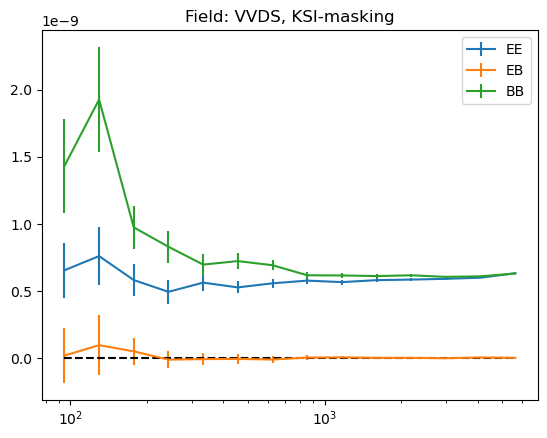

In [ ]:
plt.errorbar(ls, EE_rm, EE_std, label='EE')
plt.errorbar(ls, EB_rm, EB_std, label='EB')
plt.errorbar(ls, BB_rm, BB_std, label='BB')
# plt.plot(ls, EB, linestyle='-', label='EB')
# plt.plot(ls, BB, linestyle='-', label='BB')

plt.hlines(0, xmin=ls.min(), xmax=ls.max(), colors='k', linestyles='dashed')
plt.legend()
plt.semilogx()

plt.title(f'Field: {field}, {procedure_str}')
# plt.savefig(f'Rand_Cll_fig {procedure_str}.pdf')

Text(0.5, 1.0, 'Field: VVDS, KSI-masking')

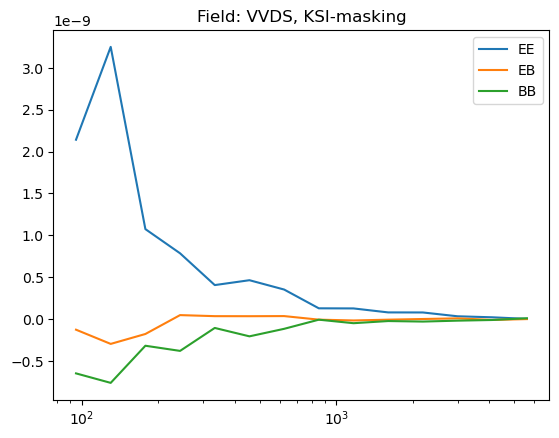

In [ ]:
plt.plot(ls, EE - EE_rm, linestyle='-', label='EE')
plt.plot(ls, EB - EB_rm, linestyle='-', label='EB')
plt.plot(ls, BB - BB_rm, linestyle='-', label='BB')
plt.legend()
plt.semilogx()

plt.title(f'Field: {field}, {procedure_str}')
# plt.savefig(f'figs/Rand_sub_Cll_fig {procedure_str}.pdf')

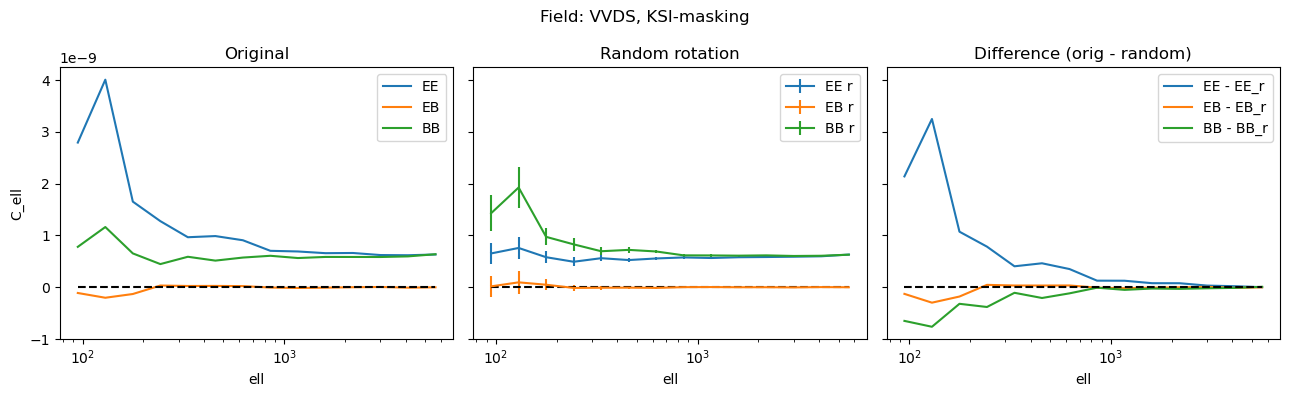

In [ ]:
fig, axs = plt.subplots(1, 3, figsize=(13, 4), sharey=True)

fig.suptitle(f'Field: {field}, {procedure_str}')
# original
axs[0].plot(ls, EE, '-', label='EE')
axs[0].plot(ls, EB, '-', label='EB')
axs[0].plot(ls, BB, '-', label='BB')
axs[0].hlines(0, ls.min(), ls.max(), colors='k', linestyles='--')
axs[0].set_title('Original')
axs[0].legend()
axs[0].set_xlabel('ell')
axs[0].set_ylabel('C_ell')
axs[0].semilogx()

# random
axs[1].errorbar(ls, EE_rm, EE_std, label='EE r')
axs[1].errorbar(ls, EB_rm, EB_std, label='EB r')
axs[1].errorbar(ls, BB_rm, BB_std, label='BB r')
axs[1].hlines(0, ls.min(), ls.max(), colors='k', linestyles='--')
axs[1].set_title('Random rotation')
axs[1].legend()
axs[1].set_xlabel('ell')
axs[1].semilogx()

# subtracted
axs[2].plot(ls, EE - EE_rm, '-', label='EE - EE_r')
axs[2].plot(ls, EB - EB_rm, '-', label='EB - EB_r')
axs[2].plot(ls, BB - BB_rm, '-', label='BB - BB_r')
axs[2].hlines(0, ls.min(), ls.max(), colors='k', linestyles='--')
axs[2].set_title('Difference (orig - random)')
axs[2].legend()
axs[2].set_xlabel('ell')
# axs[2].set_ylim(-2e-9, 3.5e-9)
axs[2].semilogx()

plt.tight_layout()

plt.savefig(f'figs/All_Cll_{field}_{procedure_str}.pdf')
plt.show()

trying to understand inpainting here

In [ ]:
from hsc_y3_utils.map_utils import dct2d, idct2d, erf

def inpaint_p(image, mask, niter=100, thresholding='hard'):
    """Fill in gaps in an image using the Discrete Cosine Transform (DCT).
    Parameters
    ----------
    image : Input image.
    mask :  Boolean or binary mask representing the missing pixels of `image`.
    niter : Number of iterations 
    thresholding : {'soft', 'hard'}, type of thresholding. Default is 'hard'.

    Returns Inpainted image
    """
    # Check inputs
    assert image.shape == mask.shape, "Incompatible mask."
    assert thresholding in ('soft', 'hard'), "Invalid thresholding."

    # Enforce binary mask condition
    mask = mask.astype(bool).astype(float)

    # Set threshold limits
    lmax = np.max(np.abs(dct2d(image, norm='ortho')))
    lmin = 0

    # Do iterative inpainting
    result = np.zeros_like(image)
    for ii in range(niter):
        # Residual
        residual = image - result
        # Take a step
        update = result + mask * residual
        print(np.abs((residual / image)[mask != 0]).max())
        # Change basis with DCT
        alpha = dct2d(update, norm='ortho')
        # Threshold coefficients
        # lval = lmax - ii * (lmax - lmin) / (niter - 1)  # linear decay
        lval = lmin + (lmax - lmin) * (1 - erf(2.8 * ii / niter))  # exp decay
        # decrease from lmax to lmin

        new_alpha = np.copy(alpha)  # Can we do this without copying ?
        if thresholding == 'hard':
            new_alpha[np.abs(new_alpha) <= lval] = 0        # what does this mean?
        else:
            new_alpha = np.abs(new_alpha) - lval
            new_alpha[new_alpha < 0] = 0
            new_alpha = np.sign(alpha) * new_alpha
        # Go back to direct space
        result = idct2d(new_alpha, norm='ortho')
        # Enforce std. dev. constraint inside the mask
        std_out = result[mask.astype(bool)].std()
        std_in = result[~mask.astype(bool)].std()
        if std_in != 0:
            result[~mask.astype(bool)] *= std_out / std_in  # force the unmasked region to have same val

    return result